# KHAI PHÁ DỮ LIỆU — LAB 1 · Phần 2 · Bài 6 (Trang 45): So sánh thời gian Apriori và FP-Growth trên Groceries Dataset

            | | |
            |---|---|
            | **Sinh viên** | Phan Quốc Thắng |
            | **MSSV** | 6451071073 |
            | **Lớp** | CNTT-K64 |
            | **GVHD** | ThS. Nguyễn Thiện Dương |

            **Dữ liệu:** `data/groceries.csv` — 9835 giao dịch, 169 mặt hàng (Hahsler et al., 2006).

**Về ngưỡng min_sup:** đề ghi “min_sup từ 0.01% đến 0.1%”. Nếu hiểu theo đúng phần trăm, min_sup = 0.01%
tương ứng support count ≈ 0.98 < 1, tức *mọi* tập con của *mọi* giao dịch (giao dịch dài nhất có 32 món
→ 2³² tập con) đều phổ biến — bùng nổ tổ hợp, không thuật toán nào liệt kê hết được. Vì vậy bài làm dùng
**min_sup ∈ {0.01, 0.02, …, 0.1}** (tức 1% → 10%) làm thí nghiệm chính, và bổ sung một thí nghiệm ở
ngưỡng thấp **0.1% → 0.9%** (giới hạn trên đúng bằng mốc 0.1% của đề) để thấy rõ chênh lệch giữa hai thuật toán.

Câu 1 ↔ yêu cầu a, Câu 2 ↔ b, Câu 3 ↔ c.

## Khai báo thông tin sinh viên & thư viện

In [1]:
HO_TEN = "Phan Quốc Thắng"
MSSV = "6451071073"
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")

import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
sns.set_theme(style="whitegrid")
SEED = int(MSSV[-4:])          # seed lấy từ MSSV để kết quả tái lập được
rng = np.random.default_rng(SEED)
DATA = "../data/"

from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth

with open(DATA + "groceries.csv", encoding="utf-8") as f:
    transactions = [line.strip().split(",") for line in f if line.strip()]
te = TransactionEncoder()
X = pd.DataFrame(te.fit(transactions).transform(transactions), columns=te.columns_)
print("Số giao dịch:", X.shape[0], "| Số mặt hàng:", X.shape[1],
      "| Số món nhiều nhất trong 1 giao dịch:", max(map(len, transactions)))
display(X.iloc[:5, :10].astype(int))

SUP_MAIN = np.round(np.arange(0.01, 0.1001, 0.01), 2)      # 1% .. 10%
SUP_LOW = np.round(np.arange(0.001, 0.0091, 0.001), 3)     # 0.1% .. 0.9%

def do_thoi_gian(algo, min_sup, lap=3):
    """Chạy thuật toán `lap` lần, trả về (số tập phổ biến, thời gian nhỏ nhất)."""
    best, n = np.inf, 0
    for _ in range(lap):
        t0 = time.perf_counter()
        fi = algo(X, min_support=min_sup, use_colnames=True)
        best = min(best, time.perf_counter() - t0); n = len(fi)
    return n, best

Họ tên: Phan Quốc Thắng - MSSV: 6451071073


Số giao dịch: 9835 | Số mặt hàng: 169 | Số món nhiều nhất trong 1 giao dịch: 32


,Instant food products,UHT-milk,abrasive cleaner,artif. sweetener,baby cosmetics,baby food,bags,baking powder,bathroom cleaner,beef
0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0


## Câu 1: (a) Tìm tập phổ biến bằng Apriori với từng min_sup và ghi nhận thời gian xử lý

In [2]:
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")
kq_ap = []
for s in SUP_MAIN:
    n, t = do_thoi_gian(apriori, s)
    kq_ap.append({"min_sup": s, "so_tap_pho_bien": n, "thoi_gian_s": t})
kq_ap = pd.DataFrame(kq_ap)
print("Thí nghiệm chính (Apriori):"); display(kq_ap.round(4))

kq_ap_low = []
for s in SUP_LOW:
    n, t = do_thoi_gian(apriori, s)
    kq_ap_low.append({"min_sup": s, "so_tap_pho_bien": n, "thoi_gian_s": t})
kq_ap_low = pd.DataFrame(kq_ap_low)
print("Thí nghiệm bổ sung ở ngưỡng thấp (Apriori):"); display(kq_ap_low.round(4))
print("Ví dụ 10 tập phổ biến lớn nhất ở min_sup = 1%:")
display(apriori(X, min_support=0.01, use_colnames=True).sort_values("support", ascending=False).head(10))

Họ tên: Phan Quốc Thắng - MSSV: 6451071073


Thí nghiệm chính (Apriori):


,min_sup,so_tap_pho_bien,thoi_gian_s
0,0.01,333,0.0736
1,0.02,122,0.0300
2,0.03,63,0.0176
3,0.04,41,0.0099
4,0.05,31,0.0077
5,0.06,21,0.0050
6,0.07,19,0.0044
7,0.08,13,0.0027
8,0.09,10,0.0018
9,0.10,8,0.0016


Thí nghiệm bổ sung ở ngưỡng thấp (Apriori):


,min_sup,so_tap_pho_bien,thoi_gian_s
0,0.001,13492,1.7042
1,0.002,4223,0.5792
2,0.003,2226,0.3439
3,0.004,1398,0.2403
4,0.005,1001,0.1801
5,0.006,747,0.1377
6,0.007,594,0.1154
7,0.008,485,0.1010
8,0.009,404,0.0831


Ví dụ 10 tập phổ biến lớn nhất ở min_sup = 1%:


,support,itemsets
86,0.255516,frozenset({whole milk})
55,0.193493,frozenset({other vegetables})
66,0.183935,frozenset({rolls/buns})
75,0.174377,frozenset({soda})
87,0.139502,frozenset({yogurt})
6,0.110524,frozenset({bottled water})
67,0.108998,frozenset({root vegetables})
81,0.104931,frozenset({tropical fruit})
73,0.098526,frozenset({shopping bags})
70,0.093950,frozenset({sausage})


**Nhận xét:**

- Dữ liệu có **9 835 giao dịch, 169 mặt hàng**, giao dịch dài nhất có 32 món. Mặt hàng phổ biến nhất là whole milk (25.6%), other vegetables (19.3%), rolls/buns (18.4%).
- Số tập phổ biến giảm rất nhanh khi min_sup tăng: 333 tập ở 1%, chỉ còn 8 tập ở 10%. Ngược lại, ở ngưỡng thấp số tập bùng nổ: 404 tập ở 0.9%, 13 492 tập ở 0.1%.

## Câu 2: (b) Tìm tập phổ biến bằng FP-Growth với từng min_sup và ghi nhận thời gian xử lý

In [3]:
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")
kq_fp = []
for s in SUP_MAIN:
    n, t = do_thoi_gian(fpgrowth, s)
    kq_fp.append({"min_sup": s, "so_tap_pho_bien": n, "thoi_gian_s": t})
kq_fp = pd.DataFrame(kq_fp)
print("Thí nghiệm chính (FP-Growth):"); display(kq_fp.round(4))

kq_fp_low = []
for s in SUP_LOW:
    n, t = do_thoi_gian(fpgrowth, s)
    kq_fp_low.append({"min_sup": s, "so_tap_pho_bien": n, "thoi_gian_s": t})
kq_fp_low = pd.DataFrame(kq_fp_low)
print("Thí nghiệm bổ sung ở ngưỡng thấp (FP-Growth):"); display(kq_fp_low.round(4))
print("Số tập phổ biến của hai thuật toán trùng nhau ở mọi ngưỡng:",
      (kq_ap["so_tap_pho_bien"].values == kq_fp["so_tap_pho_bien"].values).all() and
      (kq_ap_low["so_tap_pho_bien"].values == kq_fp_low["so_tap_pho_bien"].values).all())

Họ tên: Phan Quốc Thắng - MSSV: 6451071073


Thí nghiệm chính (FP-Growth):


,min_sup,so_tap_pho_bien,thoi_gian_s
0,0.01,333,0.0666
1,0.02,122,0.0514
2,0.03,63,0.0421
3,0.04,41,0.0369
4,0.05,31,0.0322
5,0.06,21,0.0272
6,0.07,19,0.0253
7,0.08,13,0.0219
8,0.09,10,0.0205
9,0.10,8,0.0204


Thí nghiệm bổ sung ở ngưỡng thấp (FP-Growth):


,min_sup,so_tap_pho_bien,thoi_gian_s
0,0.001,13492,0.3668
1,0.002,4223,0.1711
2,0.003,2226,0.1314
3,0.004,1398,0.1148
4,0.005,1001,0.0958
5,0.006,747,0.0861
6,0.007,594,0.0775
7,0.008,485,0.0834
8,0.009,404,0.0774


Số tập phổ biến của hai thuật toán trùng nhau ở mọi ngưỡng: True


**Nhận xét:**

- FP-Growth tìm được **đúng cùng số tập phổ biến** với Apriori ở mọi ngưỡng. Kết quả này đúng như lý thuyết: hai thuật toán khác cách duyệt nhưng cho cùng kết quả.

## Câu 3: (c) Biểu đồ so sánh thời gian xử lý của Apriori và FP-Growth

Họ tên: Phan Quốc Thắng - MSSV: 6451071073


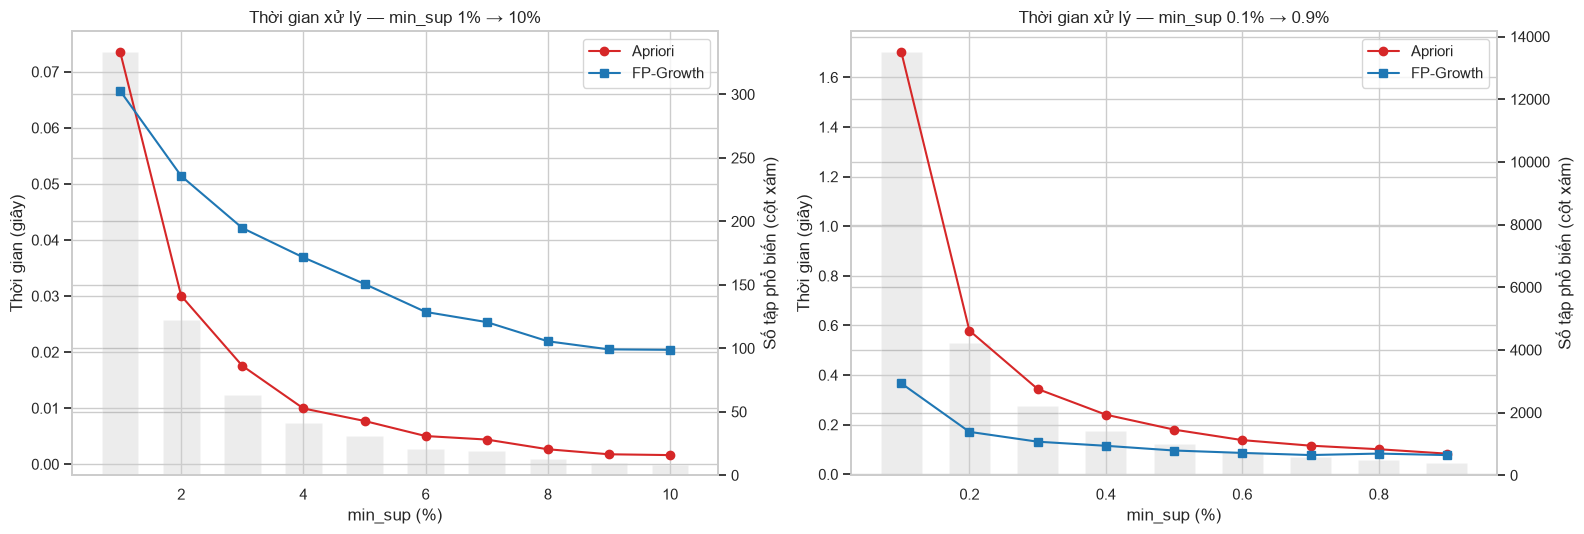

,min_sup,so_tap_pho_bien,Apriori_s,FPGrowth_s,Apriori/FPGrowth
0,0.001,13492,1.7042,0.3668,4.6460
1,0.002,4223,0.5792,0.1711,3.3855
2,0.003,2226,0.3439,0.1314,2.6177
3,0.004,1398,0.2403,0.1148,2.0928
4,0.005,1001,0.1801,0.0958,1.8790
5,0.006,747,0.1377,0.0861,1.5995
6,0.007,594,0.1154,0.0775,1.4880
7,0.008,485,0.1010,0.0834,1.2106
8,0.009,404,0.0831,0.0774,1.0748
9,0.010,333,0.0736,0.0666,1.1049


In [4]:
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, ap, fp, ten in [(axes[0], kq_ap, kq_fp, "min_sup 1% → 10%"), (axes[1], kq_ap_low, kq_fp_low, "min_sup 0.1% → 0.9%")]:
    ax.plot(ap["min_sup"] * 100, ap["thoi_gian_s"], "o-", label="Apriori", color="tab:red")
    ax.plot(fp["min_sup"] * 100, fp["thoi_gian_s"], "s-", label="FP-Growth", color="tab:blue")
    ax2 = ax.twinx()
    ax2.bar(ap["min_sup"] * 100, ap["so_tap_pho_bien"], width=(ap["min_sup"].iloc[1] - ap["min_sup"].iloc[0]) * 60,
            alpha=0.15, color="gray", label="Số tập phổ biến")
    ax2.set_ylabel("Số tập phổ biến (cột xám)")
    ax.set_zorder(ax2.get_zorder() + 1); ax.patch.set_visible(False)
    ax.set_title(f"Thời gian xử lý — {ten}"); ax.set_xlabel("min_sup (%)"); ax.set_ylabel("Thời gian (giây)"); ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

ss = pd.concat([kq_ap_low, kq_ap]).reset_index(drop=True)[["min_sup", "so_tap_pho_bien"]]
ss["Apriori_s"] = pd.concat([kq_ap_low, kq_ap])["thoi_gian_s"].values
ss["FPGrowth_s"] = pd.concat([kq_fp_low, kq_fp])["thoi_gian_s"].values
ss["Apriori/FPGrowth"] = ss["Apriori_s"] / ss["FPGrowth_s"]
display(ss.round(4))

**Nhận xét:**

- **Ngưỡng 1% → 10%**: Apriori nhanh hơn FP-Growth, ví dụ 0.030 s so với 0.051 s ở 2%, và 0.0016 s so với 0.020 s ở 10%. Hai đường gặp nhau ở khoảng 1% (0.074 s so với 0.067 s). Lý do: ở các ngưỡng này chỉ có 8 – 333 tập phổ biến, Apriori sinh rất ít ứng viên và đếm support bằng NumPy vectơ hoá. FP-Growth luôn tốn chi phí cố định để quét dữ liệu 2 lần và dựng cây FP, nên thời gian của nó chỉ giảm chậm (0.067 → 0.020 s).
- **Ngưỡng thấp 0.1% → 0.9%**: FP-Growth nhanh hơn rõ rệt và khoảng cách tăng khi min_sup giảm: 1.07× ở 0.9%, 1.9× ở 0.5%, 3.4× ở 0.2%, **4.6× ở 0.1%** (Apriori 1.70 s, FP-Growth 0.37 s, có 13 492 tập phổ biến). Khi min_sup giảm, số tập phổ biến và độ dài của chúng tăng theo cấp số. Apriori phải sinh và kiểm tra rất nhiều ứng viên ở mỗi mức, mỗi mức lại quét toàn bộ dữ liệu. FP-Growth nén dữ liệu vào cây FP và khai thác đệ quy trên các cây điều kiện, **không cần sinh ứng viên**.
- **Kết luận**: với dữ liệu lớn/dày hoặc min_sup thấp nên dùng FP-Growth. Với min_sup cao, ít tập phổ biến thì chênh lệch không đáng kể và Apriori (bản vectơ hoá) có thể còn nhanh hơn.